# TA-06 | Eksplorasi Mendalam Algoritma Random Forest
**Studi kasus:** Prediksi Penyakit Jantung (Heart Failure Prediction Dataset)

| | |
|---|---|
| Nama | Rizki Hasan Fauzi |
| NIM | 301240071 |
| Kelas | 5B, Teknik Informatika |
| Mata Kuliah | Pembelajaran Mesin (Dosen: Mohammad Bayu Anggara, S.Kom., M.Kom.) |

**Tujuan:** membangun satu model Random Forest yang akurat, stabil, dan dapat dijelaskan, lalu mencari konfigurasi
terbaik lewat dua eksperimen hyperparameter: jumlah pohon (`n_estimators`) dan kedalaman pohon (`max_depth`).

**Cara menjalankan:** letakkan `heart.csv` di folder `data/` (atau di folder yang sama dengan notebook), lalu pilih
*Run All*. Seluruh hasil memakai `random_state = 42` sehingga dapat direproduksi.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)   # folder untuk menyimpan grafik

## 1. Persiapan Data dan Preprocessing
### 1.1 Load Data

In [2]:
DATA_PATH = "data/heart.csv" if os.path.exists("data/heart.csv") else "heart.csv"
df = pd.read_csv(DATA_PATH)

print("Ukuran dataset (baris, kolom):", df.shape)
print()
df.info()
df.head()

Ukuran dataset (baris, kolom): (918, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Analisis Awal: Cek Ketidakseimbangan Kelas (Imbalance)

Distribusi kelas target (HeartDisease):
  Kelas 0: 410 data (44.7%)
  Kelas 1: 508 data (55.3%)
Rasio kelas mayoritas : minoritas = 1.24 : 1


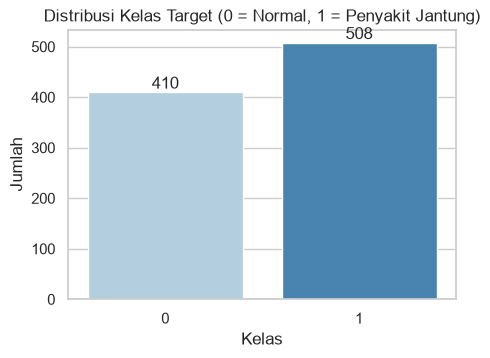

In [3]:
dist = df["HeartDisease"].value_counts().sort_index()
persen = (dist / len(df) * 100).round(1)

print("Distribusi kelas target (HeartDisease):")
for k in dist.index:
    print(f"  Kelas {k}: {dist[k]} data ({persen[k]}%)")
print(f"Rasio kelas mayoritas : minoritas = {dist.max() / dist.min():.2f} : 1")

plt.figure(figsize=(5, 3.5))
ax = sns.countplot(x="HeartDisease", data=df, hue="HeartDisease", palette="Blues", legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Kelas Target (0 = Normal, 1 = Penyakit Jantung)")
plt.xlabel("Kelas")
plt.ylabel("Jumlah")
plt.savefig("figures/01_distribusi_kelas.png", dpi=150, bbox_inches="tight")
plt.show()

Kelas target relatif seimbang (rasio sekitar 1,2 : 1), sehingga tidak diperlukan teknik *resampling* dan
**akurasi** masih layak dipakai sebagai metrik utama. Meski begitu, *precision*, *recall*, dan *F1-score* per kelas
tetap dilaporkan di bagian evaluasi akhir.

### 1.3 Pemeriksaan Nilai Tidak Wajar
Kadar kolesterol dan tekanan darah istirahat bernilai 0 tidak mungkin terjadi secara medis. Nilai 0 tersebut
diperlakukan sebagai data hilang dan akan diisi dengan median.

In [4]:
for kol in ["Cholesterol", "RestingBP"]:
    print(f"{kol}: {(df[kol] == 0).sum()} baris bernilai 0")

nol_kol = df[df["Cholesterol"] == 0]["HeartDisease"].value_counts().sort_index()
print()
print("Sebaran kelas pada baris dengan Cholesterol = 0:", nol_kol.to_dict())
print("Proporsi kelas 1 pada baris tersebut: {:.1%} (keseluruhan data: {:.1%})".format(
    (df[df["Cholesterol"] == 0]["HeartDisease"]).mean(), df["HeartDisease"].mean()))

Cholesterol: 172 baris bernilai 0
RestingBP: 1 baris bernilai 0

Sebaran kelas pada baris dengan Cholesterol = 0: {0: 20, 1: 152}
Proporsi kelas 1 pada baris tersebut: 88.4% (keseluruhan data: 55.3%)


### 1.4 Encoding, Split Data (80% / 20%), dan Imputasi
Urutan pengerjaan:
1. **One-Hot Encoding** untuk semua kolom kategorik.
2. Nilai 0 pada `Cholesterol` dan `RestingBP` diubah menjadi `NaN`.
3. **Split** 80% data latih dan 20% data uji dengan `stratify=y` agar proporsi kelas terjaga.
4. **Imputasi median** dihitung **hanya dari data latih**, lalu diterapkan ke data latih dan data uji
   (mencegah kebocoran data / *data leakage*).

In [5]:
target = "HeartDisease"
kolom_kategorik = df.select_dtypes(exclude="number").columns.tolist()
print("Kolom kategorik:", kolom_kategorik)

# 1) One-Hot Encoding
X = pd.get_dummies(df.drop(columns=target), columns=kolom_kategorik, dtype=int)
y = df[target]

# 2) Nilai 0 yang tidak wajar dianggap hilang
for kol in ["Cholesterol", "RestingBP"]:
    X[kol] = X[kol].replace(0, np.nan)

# 3) Split 80% latih / 20% uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# 4) Imputasi median dari data latih saja
median_latih = X_train[["Cholesterol", "RestingBP"]].median()
X_train = X_train.fillna(median_latih)
X_test = X_test.fillna(median_latih)

print()
print("Median imputasi (dari data latih):")
print(median_latih.to_string())
print()
print("Jumlah fitur setelah encoding :", X_train.shape[1])
print("Data latih :", X_train.shape, "| Data uji :", X_test.shape)
print("Sisa nilai kosong (latih, uji):", int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print("Proporsi kelas 1 -> latih: {:.3f} | uji: {:.3f}".format(y_train.mean(), y_test.mean()))

Kolom kategorik: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Median imputasi (dari data latih):
Cholesterol    238.0
RestingBP      130.0

Jumlah fitur setelah encoding : 20
Data latih : (734, 20) | Data uji : (184, 20)
Sisa nilai kosong (latih, uji): 0 0
Proporsi kelas 1 -> latih: 0.553 | uji: 0.554


## 2. Modeling dan Eksperimen Hyperparameter
Selain akurasi training dan testing (sesuai ketentuan tugas), dicatat juga **akurasi cross-validation 5-fold pada
data latih**. Nilai ini dipakai untuk memilih konfigurasi terbaik, sebab memilih berdasarkan data uji saja berarti
"mengintip" data uji (*test set tuning*). Data uji tetap dipakai untuk pelaporan.

**Aturan pemilihan konfigurasi (parsimoni):** dari semua kandidat, ambil yang **paling sederhana**
(pohon paling sedikit / paling dangkal) di antara yang akurasi CV-nya berada dalam **0,5 poin persen** dari nilai
CV tertinggi. Alasannya, perbedaan sekecil itu masih lebih kecil daripada simpangan baku CV (sekitar 3 poin persen),
sehingga model yang lebih sederhana lebih layak dipilih: lebih cepat, lebih hemat memori, dan selisih
training-testing-nya lebih kecil.

### Skenario A: Pengaruh Jumlah Pohon (`n_estimators`)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
TOLERANSI = 0.005   # toleransi akurasi CV untuk aturan parsimoni (0,5 poin persen)

daftar_n = [10, 50, 100, 200, 500]
hasil_a = []

for n in daftar_n:
    rf = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train, y_train)

    skor_cv = cross_val_score(
        RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1),
        X_train, y_train, cv=cv, scoring="accuracy"
    )
    hasil_a.append({
        "n_estimators": n,
        "Akurasi Training": accuracy_score(y_train, rf.predict(X_train)),
        "Akurasi Testing": accuracy_score(y_test, rf.predict(X_test)),
        "Akurasi CV (5-fold)": skor_cv.mean(),
        "Std CV": skor_cv.std(),
    })

df_a = pd.DataFrame(hasil_a).round(4)
df_a

,n_estimators,Akurasi Training,Akurasi Testing,Akurasi CV (5-fold),Std CV
0,10,0.9905,0.8750,0.8406,0.0279
1,50,1.0000,0.8804,0.8488,0.0313
2,100,1.0000,0.8804,0.8515,0.0279
3,200,1.0000,0.8804,0.8515,0.0307
4,500,1.0000,0.8859,0.8529,0.0299


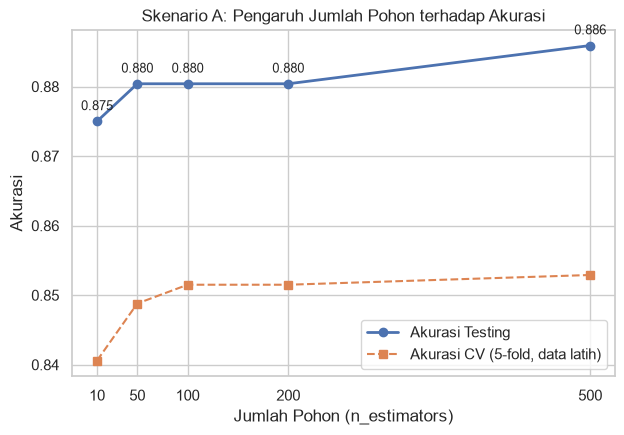

Rentang akurasi testing antar konfigurasi: 0.0109 (1.09 poin persen)
CV tertinggi: 0.8529 pada n_estimators = 500
Kandidat dalam toleransi 0.005: [50, 100, 200, 500]
n_estimators terpilih (paling sederhana): 50


In [7]:
plt.figure(figsize=(7, 4.5))
plt.plot(df_a["n_estimators"], df_a["Akurasi Testing"], marker="o", linewidth=2, label="Akurasi Testing")
plt.plot(df_a["n_estimators"], df_a["Akurasi CV (5-fold)"], marker="s", linestyle="--", label="Akurasi CV (5-fold, data latih)")
for x, yv in zip(df_a["n_estimators"], df_a["Akurasi Testing"]):
    plt.annotate(f"{yv:.3f}", (x, yv), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.xticks(daftar_n)
plt.xlabel("Jumlah Pohon (n_estimators)")
plt.ylabel("Akurasi")
plt.title("Skenario A: Pengaruh Jumlah Pohon terhadap Akurasi")
plt.legend()
plt.savefig("figures/02_skenario_a_n_estimators.png", dpi=150, bbox_inches="tight")
plt.show()

selisih = df_a["Akurasi Testing"].max() - df_a["Akurasi Testing"].min()
print(f"Rentang akurasi testing antar konfigurasi: {selisih:.4f} ({selisih * 100:.2f} poin persen)")

# n_estimators terpilih = paling sedikit pohon di antara yang CV-nya dalam TOLERANSI dari CV tertinggi
cv_a = df_a["Akurasi CV (5-fold)"]
n_cv_puncak = int(df_a.loc[cv_a.idxmax(), "n_estimators"])
kandidat_a = df_a[cv_a >= cv_a.max() - TOLERANSI]
best_n = int(kandidat_a["n_estimators"].min())
print(f"CV tertinggi: {cv_a.max():.4f} pada n_estimators = {n_cv_puncak}")
print(f"Kandidat dalam toleransi {TOLERANSI}: {kandidat_a['n_estimators'].tolist()}")
print("n_estimators terpilih (paling sederhana):", best_n)

### Skenario B: Pengaruh Kedalaman Pohon (`max_depth`)
Memakai `n_estimators` terbaik dari Skenario A.

In [8]:
daftar_depth = [None, 3, 5, 10, 20]
hasil_b = []

for d in daftar_depth:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train, y_train)

    skor_cv = cross_val_score(
        RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1),
        X_train, y_train, cv=cv, scoring="accuracy"
    )
    tr = accuracy_score(y_train, rf.predict(X_train))
    te = accuracy_score(y_test, rf.predict(X_test))
    hasil_b.append({
        "max_depth": "None (Unlimited)" if d is None else d,
        "Kedalaman asli (rata-rata)": np.mean([e.get_depth() for e in rf.estimators_]),
        "Akurasi Training": tr,
        "Akurasi Testing": te,
        "Selisih (Train - Test)": tr - te,
        "Akurasi CV (5-fold)": skor_cv.mean(),
    })

df_b = pd.DataFrame(hasil_b).round(4)
df_b

,max_depth,Kedalaman asli (rata-rata),Akurasi Training,Akurasi Testing,Selisih (Train - Test),Akurasi CV (5-fold)
0,None (Unlimited),13.72,1.0000,0.8804,0.1196,0.8488
1,3,3.00,0.8638,0.8587,0.0051,0.8447
2,5,5.00,0.8951,0.8750,0.0201,0.8515
3,10,10.00,0.9891,0.8913,0.0978,0.8665
4,20,13.72,1.0000,0.8804,0.1196,0.8488


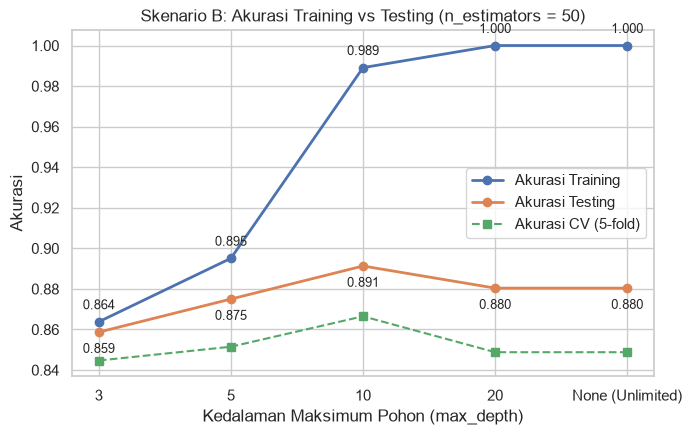

CV tertinggi: 0.8665 pada max_depth = 10
Kandidat dalam toleransi: [10]
max_depth terpilih (paling sederhana): 10


In [9]:
# tampilkan 3, 5, 10, 20, None (menaik) agar tren lebih mudah dibaca
db = df_b.iloc[[1, 2, 3, 4, 0]]
label_x = [str(v) for v in db["max_depth"]]
x_pos = np.arange(len(label_x))

plt.figure(figsize=(7.5, 4.5))
plt.plot(x_pos, db["Akurasi Training"], marker="o", linewidth=2, label="Akurasi Training")
plt.plot(x_pos, db["Akurasi Testing"], marker="o", linewidth=2, label="Akurasi Testing")
plt.plot(x_pos, db["Akurasi CV (5-fold)"], marker="s", linestyle="--", label="Akurasi CV (5-fold)")
for x, yv in zip(x_pos, db["Akurasi Training"]):
    plt.annotate(f"{yv:.3f}", (x, yv), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
for x, yv in zip(x_pos, db["Akurasi Testing"]):
    plt.annotate(f"{yv:.3f}", (x, yv), textcoords="offset points", xytext=(0, -15), ha="center", fontsize=9)
plt.xticks(x_pos, label_x)
plt.xlabel("Kedalaman Maksimum Pohon (max_depth)")
plt.ylabel("Akurasi")
plt.title(f"Skenario B: Akurasi Training vs Testing (n_estimators = {best_n})")
plt.legend(loc="center right")
plt.savefig("figures/03_skenario_b_max_depth.png", dpi=150, bbox_inches="tight")
plt.show()

# max_depth terpilih = paling dangkal di antara yang CV-nya dalam TOLERANSI dari CV tertinggi
nilai_depth = [np.inf if d is None else d for d in daftar_depth]
cv_b = df_b["Akurasi CV (5-fold)"].to_numpy()
kandidat = [i for i in range(len(daftar_depth)) if cv_b[i] >= cv_b.max() - TOLERANSI]
idx_best = min(kandidat, key=lambda i: nilai_depth[i])
best_depth = daftar_depth[idx_best]
print(f"CV tertinggi: {cv_b.max():.4f} pada max_depth = {daftar_depth[int(cv_b.argmax())]}")
print("Kandidat dalam toleransi:", [daftar_depth[i] for i in kandidat])
print("max_depth terpilih (paling sederhana):", best_depth)

## 3. Analisis Feature Importance
Memakai model terbaik dari dua eksperimen di atas (`n_estimators` dan `max_depth` terbaik).

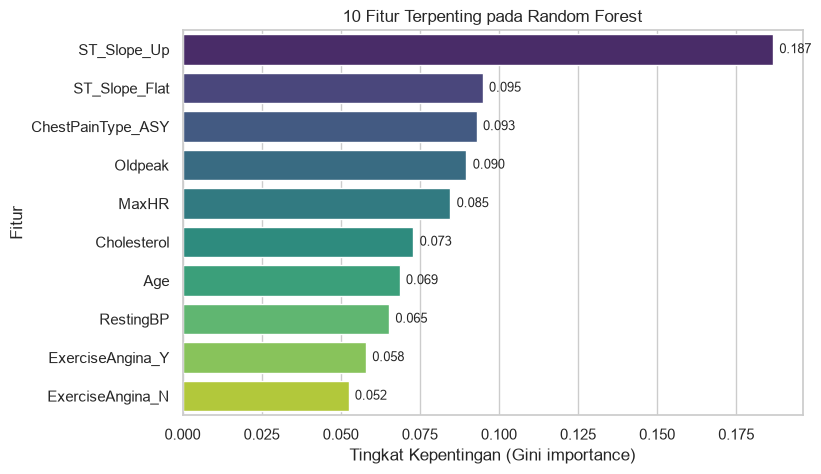

Total importance 10 fitur teratas: 0.866 dari 1.000


,Importance
ST_Slope_Up,0.1866
ST_Slope_Flat,0.0949
ChestPainType_ASY,0.0930
Oldpeak,0.0897
MaxHR,0.0846
Cholesterol,0.0729
Age,0.0686
RestingBP,0.0653
ExerciseAngina_Y,0.0580
ExerciseAngina_N,0.0525


In [10]:
model = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, oob_score=True,
                               random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train, y_train)

importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top10 = importances.head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="viridis", legend=False)
for i, v in enumerate(top10.values):
    plt.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
plt.xlabel("Tingkat Kepentingan (Gini importance)")
plt.ylabel("Fitur")
plt.title("10 Fitur Terpenting pada Random Forest")
plt.savefig("figures/04_feature_importance_top10.png", dpi=150, bbox_inches="tight")
plt.show()

print("Total importance 10 fitur teratas: {:.3f} dari 1.000".format(top10.sum()))
top10.round(4).to_frame("Importance")

In [11]:
# One-Hot Encoding memecah satu variabel menjadi beberapa kolom, sehingga importance dijumlahkan per variabel asli
def kolom_asal(nama):
    for kat in kolom_kategorik:
        if nama.startswith(kat + "_"):
            return kat
    return nama

grup = importances.groupby(kolom_asal).sum().sort_values(ascending=False)
print("Importance per variabel asli (jumlah dari kolom hasil One-Hot Encoding):")
grup.round(4).to_frame("Importance")

Importance per variabel asli (jumlah dari kolom hasil One-Hot Encoding):


,Importance
ST_Slope,0.2886
ChestPainType,0.1228
ExerciseAngina,0.1104
Oldpeak,0.0897
MaxHR,0.0846
Cholesterol,0.0729
Age,0.0686
RestingBP,0.0653
Sex,0.0449
RestingECG,0.0293


In [12]:
# Pembanding: permutation importance pada data uji (lebih tahan terhadap bias Gini importance)
hasil_perm = permutation_importance(model, X_test, y_test, n_repeats=10,
                                    random_state=RANDOM_STATE, scoring="accuracy", n_jobs=-1)
perm = pd.Series(hasil_perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("Permutation importance (penurunan akurasi rata-rata saat fitur diacak), 10 teratas:")
perm.head(10).round(4).to_frame("Penurunan akurasi")

Permutation importance (penurunan akurasi rata-rata saat fitur diacak), 10 teratas:


,Penurunan akurasi
ST_Slope_Up,0.0538
ChestPainType_ASY,0.0467
Sex_F,0.0299
Oldpeak,0.0239
ST_Slope_Flat,0.0196
Sex_M,0.0179
Cholesterol,0.0163
MaxHR,0.0152
RestingBP,0.0152
ExerciseAngina_Y,0.0130


In [13]:
# Cek apakah pola yang ditangkap model benar-benar ada di data: proporsi penyakit jantung per kategori
for kol in ["ST_Slope", "ChestPainType", "ExerciseAngina"]:
    tabel = df.groupby(kol)["HeartDisease"].agg(proporsi_kelas_1="mean", jumlah="count").round(3)
    print(tabel.to_string())
    print()

print("Rata-rata fitur numerik per kelas:")
df.groupby("HeartDisease")[["MaxHR", "Oldpeak", "Age"]].mean().round(2)

          proporsi_kelas_1  jumlah
ST_Slope                          
Down                 0.778      63
Flat                 0.828     460
Up                   0.197     395

               proporsi_kelas_1  jumlah
ChestPainType                          
ASY                       0.790     496
ATA                       0.139     173
NAP                       0.355     203
TA                        0.435      46

                proporsi_kelas_1  jumlah
ExerciseAngina                          
N                          0.351     547
Y                          0.852     371

Rata-rata fitur numerik per kelas:


,MaxHR,Oldpeak,Age
HeartDisease,,,
0,148.15,0.41,50.55
1,127.66,1.27,55.90


## 4. Evaluasi Akhir

Konfigurasi model terbaik: n_estimators = 50 | max_depth = 10
Akurasi Training: 0.9891
Akurasi Testing : 0.8913
Akurasi OOB     : 0.8474 (estimasi bawaan Random Forest dari data latih)

Classification Report (data uji, 184 sampel):
                      precision    recall  f1-score   support

          Normal (0)      0.887     0.866     0.877        82
Penyakit Jantung (1)      0.894     0.912     0.903       102

            accuracy                          0.891       184
           macro avg      0.891     0.889     0.890       184
        weighted avg      0.891     0.891     0.891       184



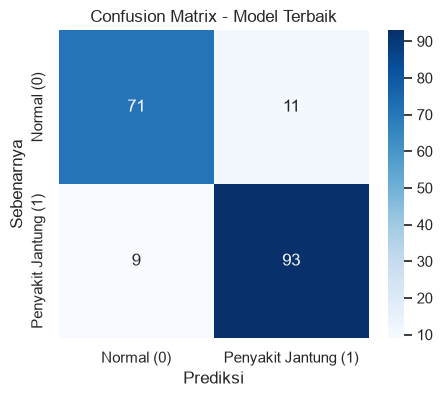

TN = 71 | FP = 11 | FN = 9 | TP = 93


In [14]:
y_pred = model.predict(X_test)
nama_kelas = ["Normal (0)", "Penyakit Jantung (1)"]

print("Konfigurasi model terbaik: n_estimators =", best_n, "| max_depth =", best_depth)
print("Akurasi Training:", round(accuracy_score(y_train, model.predict(X_train)), 4))
print("Akurasi Testing :", round(accuracy_score(y_test, y_pred), 4))
print("Akurasi OOB     :", round(model.oob_score_, 4), "(estimasi bawaan Random Forest dari data latih)")
print()
print("Classification Report (data uji, %d sampel):" % len(y_test))
print(classification_report(y_test, y_pred, target_names=nama_kelas, digits=3))

laporan = classification_report(y_test, y_pred, target_names=nama_kelas, output_dict=True)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nama_kelas, yticklabels=nama_kelas)
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.title("Confusion Matrix - Model Terbaik")
plt.savefig("figures/05_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

In [15]:
print("RINGKASAN KONFIGURASI TERBAIK")
print("  n_estimators :", best_n)
print("  max_depth    :", best_depth)
print("  Akurasi CV (5-fold, data latih):", float(df_b.loc[idx_best, "Akurasi CV (5-fold)"]))
print("  Akurasi testing                :", round(accuracy_score(y_test, y_pred), 4))
print("  Fitur teratas                  :", ", ".join(importances.head(3).index))

RINGKASAN KONFIGURASI TERBAIK
  n_estimators : 50
  max_depth    : 10
  Akurasi CV (5-fold, data latih): 0.8665
  Akurasi testing                : 0.8913
  Fitur teratas                  : ST_Slope_Up, ST_Slope_Flat, ChestPainType_ASY


## 5. Interpretasi dan Kesimpulan

### 5.1 Skenario A: apakah menambah pohon terus-menerus meningkatkan akurasi?
**Tidak secara signifikan.** Akurasi CV naik dari 0,8406 (10 pohon) menjadi 0,8488 (50 pohon) lalu hampir mendatar di
kisaran 0,8515 sampai 0,8529 untuk 100 sampai 500 pohon. Akurasi testing hanya bergerak dari 0,8750 ke 0,8859, yaitu
selisih 1,09 poin persen atau sekitar 2 dari 184 sampel uji, jauh di bawah simpangan baku CV (sekitar 3 poin persen).
Artinya, setelah sekitar 50 sampai 100 pohon, tambahan pohon hanya menambah waktu komputasi dan memori tanpa manfaat
yang berarti. Berdasarkan aturan parsimoni, dipilih **`n_estimators = 50`**.

### 5.2 Skenario B: pada kedalaman berapa mulai overfitting?
- Selisih akurasi training dan testing **melebar tajam di antara `max_depth` 5 (2,0 poin) dan 10 (9,8 poin)**, lalu
  mencapai 12,0 poin pada `max_depth = 20` dan `None`.
- Akurasi **testing baru turun** pada `max_depth` 20 / `None` (0,8804) dibanding `max_depth = 10` (0,8913). Jadi
  *overfitting* yang merugikan mulai terlihat pada kedalaman **di atas 10**, sedangkan pada kedalaman 10 model masih
  menjadi yang terbaik di CV (0,8665) maupun di data uji.
- `max_depth = 20` identik dengan `None` karena rata-rata kedalaman pohon yang terbentuk hanya sekitar 13,7, sehingga batas 20
  tidak pernah tercapai.
- Akurasi training mendekati 1,0 pada Random Forest sebagian besar karena setiap pohon sudah "melihat" sekitar 63%
  data latih (*bootstrap*), sehingga akurasi training bukan ukuran generalisasi yang jujur. Ukuran yang lebih jujur
  adalah akurasi OOB, CV, dan testing, yang berada di kisaran 0,85 sampai 0,89.

### 5.3 Interpretasi Feature Importance
Fitur terpenting menurut model adalah `ST_Slope` (jumlah importance 0,289), `ChestPainType` (0,123), dan
`ExerciseAngina` (0,110), diikuti `Oldpeak` (0,090) dan `MaxHR` (0,085). Pola ini **sesuai dengan data**: proporsi
pasien berpenyakit jantung mencapai 82,8% pada `ST_Slope = Flat` dan 77,8% pada `Down`, tetapi hanya 19,7% pada `Up`;
79,0% pada nyeri dada tanpa gejala (`ChestPainType = ASY`) dibanding 13,9% pada `ATA`; dan 85,2% pada pasien yang
mengalami angina saat olahraga dibanding 35,1% yang tidak. Pasien berpenyakit jantung juga rata-rata memiliki detak
jantung maksimum lebih rendah (127,7 vs 148,2) dan `Oldpeak` lebih tinggi (1,27 vs 0,41). Ini sejalan dengan fungsi
fitur-fitur tersebut sebagai hasil pemeriksaan elektrokardiogram saat uji olahraga. *Permutation importance* pada
data uji menghasilkan dua fitur teratas yang sama (`ST_Slope_Up` dan `ChestPainType_ASY`), sehingga temuan ini cukup
konsisten.

Catatan: pada data asli, 88,4% baris dengan `Cholesterol = 0` (152 dari 172) berasal dari kelas penyakit jantung,
jauh di atas proporsi keseluruhan (55,3%). Karena nilai 0 itu tidak wajar secara medis, nilai tersebut diperlakukan
sebagai data hilang dan diganti median latih, agar model tidak belajar dari artefak pencatatan data.

### 5.4 Kesimpulan
Konfigurasi terbaik dan stabil untuk dataset ini adalah **`n_estimators = 50` dan `max_depth = 10`**. Model ini
mencapai akurasi testing **0,8913** (OOB 0,8474 dan CV 0,8665), *precision* dan *recall* kelas penyakit jantung 0,894
dan 0,912 (F1 0,903), serta F1 kelas normal 0,877, dengan 9 *false negative* dan 11 *false positive* dari 184 sampel
uji. Perbedaan antar konfigurasi yang diuji umumnya hanya beberapa sampel uji sehingga tidak boleh dibaca sebagai
keunggulan yang pasti. Keterbatasan: evaluasi memakai satu pembagian data dengan 184 sampel uji, dan model ini
ditujukan untuk pembelajaran, bukan untuk diagnosis klinis.